In [1]:
# Import libraries for 3D mesh generation

import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.measure import marching_cubes

In [2]:
# Define dataset directories

from pathlib import Path

BASE_DIR = Path.home() / "Thesis/Data/HCUCH/final-formatted/images"

IMAGE_DIR = BASE_DIR / "abdomen/train/images"
MASK_DIR = BASE_DIR / "abdomen_fixed/train/LN.masks"

print("Image directory exists:", IMAGE_DIR.exists())
print("Mask directory exists:", MASK_DIR.exists())

Image directory exists: True
Mask directory exists: True


In [3]:
# Find matching CT and segmentation mask files

image_files = sorted(IMAGE_DIR.glob("*.nii.gz"))
mask_files = sorted(MASK_DIR.glob("*.nii.gz"))

image_lookup = {p.name: p for p in image_files}
mask_lookup = {p.name: p for p in mask_files}

common_names = sorted(set(image_lookup) & set(mask_lookup))

print("Matching CT-mask pairs:", len(common_names))

if not common_names:
    raise ValueError("No matching CT-mask pairs found.")

selected_name = common_names[0]

ct_path = image_lookup[selected_name]
mask_path = mask_lookup[selected_name]

print("Selected one matching pair.")

Matching CT-mask pairs: 12
Selected one matching pair.


In [4]:
# Load CT and mask images

import nibabel as nib
import numpy as np

ct_img = nib.load(str(ct_path))
mask_img = nib.load(str(mask_path))

print("CT and Mask loaded successfully!")

CT and Mask loaded successfully!


In [5]:
# Check CT and mask orientations and coordinate transformation

print("CT orientation:", nib.aff2axcodes(ct_img.affine))
print("Mask orientation:", nib.aff2axcodes(mask_img.affine))

print("\nCT affine:")
print(np.round(ct_img.affine, 4))

print("\nMask affine:")
print(np.round(mask_img.affine, 4))

relative_transform = np.linalg.inv(ct_img.affine) @ mask_img.affine

print("\nMask-to-CT voxel transformation:")
print(np.round(relative_transform, 4))

CT orientation: ('L', 'A', 'S')
Mask orientation: ('L', 'A', 'I')

CT affine:
[[  -0.6719   -0.        0.      177.6641]
 [   0.        0.6719    0.      -20.6641]
 [   0.        0.        2.5    -475.    ]
 [   0.        0.        0.        1.    ]]

Mask affine:
[[ -0.6719  -0.      -0.     177.6641]
 [ -0.       0.6719   0.     -20.6641]
 [  0.       0.      -2.5    -72.5   ]
 [  0.       0.       0.       1.    ]]

Mask-to-CT voxel transformation:
[[  1.   0.   0.   0.]
 [  0.   1.   0.   0.]
 [  0.   0.  -1. 161.]
 [  0.   0.   0.   1.]]


In [6]:
# Load CT and segmentation mask arrays

import numpy as np

ct_data = np.asarray(ct_img.dataobj)
mask_data = np.asarray(mask_img.dataobj)

print("CT shape:", ct_data.shape)
print("Mask shape:", mask_data.shape)

CT shape: (512, 512, 162)
Mask shape: (512, 512, 162)


In [7]:
# Align segmentation mask with CT voxel coordinates

expected_transform = np.eye(4)
expected_transform[2, 2] = -1
expected_transform[2, 3] = mask_data.shape[2] - 1

assert ct_data.shape == mask_data.shape
assert np.allclose(relative_transform, expected_transform, atol=1e-4)

mask_aligned = np.flip(mask_data, axis=2)

print("Mask aligned successfully!")
print("Aligned mask shape:", mask_aligned.shape)

Mask aligned successfully!
Aligned mask shape: (512, 512, 162)


In [8]:
# Inspect segmentation labels

labels, counts = np.unique(mask_aligned, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} voxels")

Label 0: 42453513 voxels
Label 1: 2885 voxels
Label 2: 9745 voxels
Label 3: 683 voxels
Label 4: 502 voxels


In [9]:
# Select the largest non-background label

positive = labels > 0

if not np.any(positive):
    raise ValueError("No segmented lymph nodes found.")

target_label = labels[positive][np.argmax(counts[positive])]

binary_mask = mask_aligned == target_label

print("Selected label:", target_label)
print("Number of voxels:", binary_mask.sum())

Selected label: 2
Number of voxels: 9745


In [21]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [10]:
# Generate a 3D surface mesh using Marching Cubes

from skimage.measure import marching_cubes

spacing = ct_img.header.get_zooms()[:3]

vertices, faces, normals, values = marching_cubes(
    binary_mask.astype(np.uint8),
    level=0.5,
    spacing=spacing
)

print("Mesh generated successfully!")
print("Number of vertices:", len(vertices))
print("Number of faces:", len(faces))
print("Vertices shape:", vertices.shape)
print("Faces shape:", faces.shape)

Mesh generated successfully!
Number of vertices: 5886
Number of faces: 11768
Vertices shape: (5886, 3)
Faces shape: (11768, 3)


In [24]:
%pip install plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 46.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [plotly]2m1/2 [plotly]
Note: you may need to restart the kernel to use updated packages.


In [11]:
# Check Plotly installation

import importlib.util

print("Plotly installed:", importlib.util.find_spec("plotly") is not None)

Plotly installed: True


In [27]:
# Install the missing Jupyter dependency

%pip install "nbformat>=4.2.0"

  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached jsonschema-4.26.0-py3-none-any.whl (90 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
Using cached referencing-0.37.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [nbformat]6/7 [nbformat]a]specifications]
Note: you may need to restart the kernel to use updated packages.


In [12]:
# Verify nbformat installation

import nbformat
import plotly

print("nbformat version:", nbformat.__version__)
print("Plotly version:", plotly.__version__)

nbformat version: 5.11.1
Plotly version: 7.1.0


In [13]:
# Check the active Python environment and nbformat

import sys
import importlib.util

print("Python:", sys.executable)

spec = importlib.util.find_spec("nbformat")
print("nbformat found:", spec is not None)

if spec is not None:
    import nbformat
    print("nbformat version:", nbformat.__version__)
    print("nbformat location:", nbformat.__file__)

Python: /home/stud/nasrinke/medical3d_conda/bin/python
nbformat found: True
nbformat version: 5.11.1
nbformat location: /home/stud/nasrinke/medical3d_conda/lib/python3.10/site-packages/nbformat/__init__.py


In [14]:
# Visualize the generated 3D mesh

import plotly.graph_objects as go

fig = go.Figure(
    data=[
        go.Mesh3d(
            x=vertices[:, 0],
            y=vertices[:, 1],
            z=vertices[:, 2],
            i=faces[:, 0],
            j=faces[:, 1],
            k=faces[:, 2],
            color="lightcoral",
            opacity=1.0,
            flatshading=False
        )
    ]
)

fig.update_layout(
    title="3D Lymph Node Reconstruction",
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode="data"
    ),
    width=850,
    height=650
)

fig.show()

In [15]:
# Save interactive 3D visualization as HTML

from pathlib import Path

output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

html_path = output_dir / "lymph_node_3d.html"

fig.write_html(
    str(html_path),
    include_plotlyjs=True
)

print("Saved:", html_path.resolve())

Saved: /home/stud/nasrinke/projects/medical-3d-visualization/results/lymph_node_3d.html


Selected label: 2
Number of positive slices: 12
First positive slice: 128
Last positive slice: 139


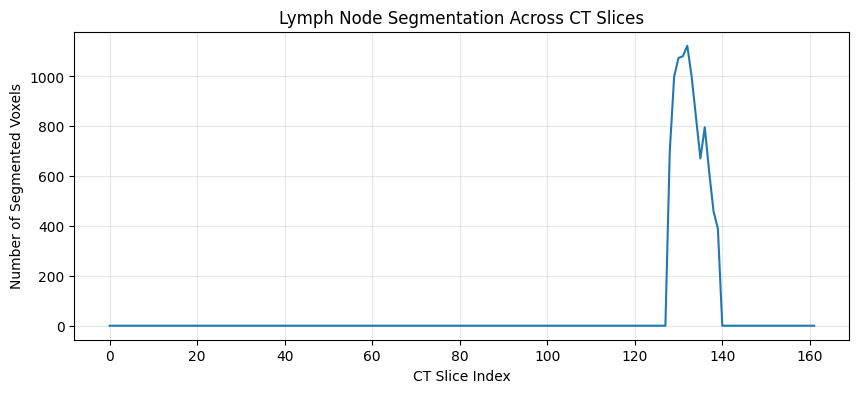

In [16]:
# Check segmentation distribution across CT slices

import numpy as np
import matplotlib.pyplot as plt

slice_counts = np.count_nonzero(
    binary_mask,
    axis=(0, 1)
)

positive_slices = np.where(slice_counts > 0)[0]

print("Selected label:", target_label)
print("Number of positive slices:", len(positive_slices))

print("First positive slice:", positive_slices.min())
print("Last positive slice:", positive_slices.max())

plt.figure(figsize=(10, 4))

plt.plot(slice_counts)

plt.xlabel("CT Slice Index")
plt.ylabel("Number of Segmented Voxels")
plt.title("Lymph Node Segmentation Across CT Slices")

plt.grid(alpha=0.3)
plt.show()

In [17]:
# Check connected components in the selected mask

from scipy import ndimage

components, num_components = ndimage.label(
    binary_mask,
    structure=ndimage.generate_binary_structure(3, 1)
)

component_sizes = np.bincount(
    components.ravel()
)[1:]

print("Number of connected components:", num_components)

print(
    "Largest component size:",
    component_sizes.max() if num_components else 0
)

print(
    "Total segmented voxels:",
    binary_mask.sum()
)

Number of connected components: 1
Largest component size: 9745
Total segmented voxels: 9745


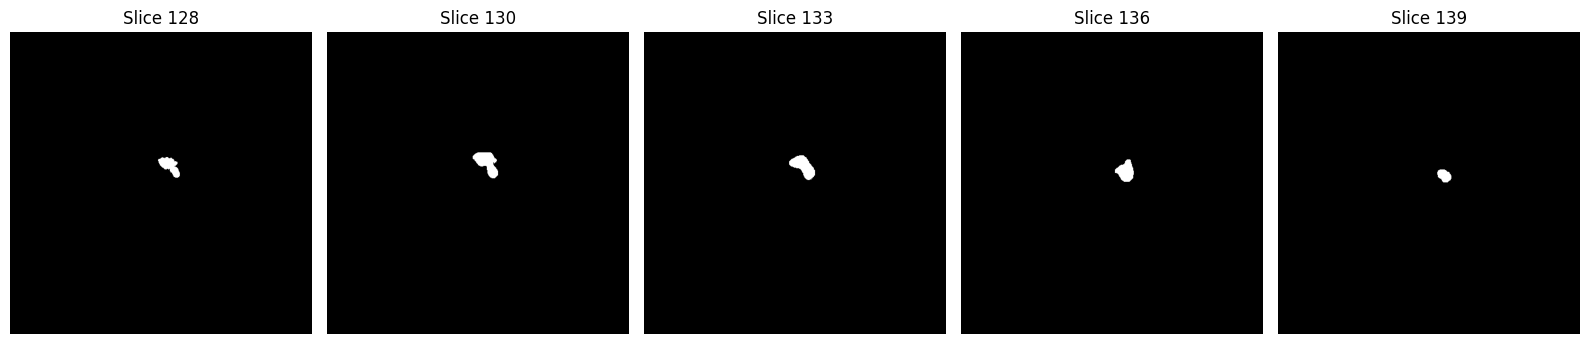

In [18]:
# Visualize selected lymph node segmentation across slices

selected_slices = np.linspace(
    positive_slices.min(),
    positive_slices.max(),
    5,
    dtype=int
)

fig_check, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, z in zip(axes, selected_slices):

    ax.imshow(
        binary_mask[:, :, z].T,
        cmap="gray",
        origin="lower"
    )

    ax.set_title(f"Slice {z}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Smooth the 3D mesh using Laplacian smoothing

import trimesh
import numpy as np

original_mesh = trimesh.Trimesh(
    vertices=vertices.copy(),
    faces=faces.copy(),
    process=False
)

smoothed_mesh = original_mesh.copy()

trimesh.smoothing.filter_laplacian(
    smoothed_mesh,
    lamb=0.3,
    iterations=5,
    volume_constraint=True
)

print("Original vertices:", len(original_mesh.vertices))
print("Smoothed vertices:", len(smoothed_mesh.vertices))

print("Original watertight:", original_mesh.is_watertight)
print("Smoothed watertight:", smoothed_mesh.is_watertight)

Original vertices: 5886
Smoothed vertices: 5886
Original watertight: True
Smoothed watertight: True


In [20]:
# Compare original and smoothed 3D meshes

import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig_compare = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("Original Mesh", "Smoothed Mesh")
)

for col, mesh, color in [
    (1, original_mesh, "lightcoral"),
    (2, smoothed_mesh, "lightblue")
]:
    fig_compare.add_trace(
        go.Mesh3d(
            x=mesh.vertices[:, 0],
            y=mesh.vertices[:, 1],
            z=mesh.vertices[:, 2],
            i=mesh.faces[:, 0],
            j=mesh.faces[:, 1],
            k=mesh.faces[:, 2],
            color=color,
            opacity=1.0
        ),
        row=1,
        col=col
    )

fig_compare.update_layout(
    title="3D Lymph Node Reconstruction: Before and After Smoothing",
    height=600,
    width=1100,
    scene=dict(aspectmode="data"),
    scene2=dict(aspectmode="data")
)

fig_compare.show()

In [21]:
# Compare mesh volume before and after smoothing

original_volume = abs(original_mesh.volume)
smoothed_volume = abs(smoothed_mesh.volume)

volume_change = (
    (smoothed_volume - original_volume)
    / original_volume
    * 100
) if original_volume > 0 else float("nan")

print(f"Original volume: {original_volume:.2f} mm³")
print(f"Smoothed volume: {smoothed_volume:.2f} mm³")
print(f"Volume change: {volume_change:.2f}%")

Original volume: 10942.37 mm³
Smoothed volume: 10942.37 mm³
Volume change: 0.00%


In [22]:
# Calculate segmentation volume directly from voxel count

voxel_volume = np.prod(ct_img.header.get_zooms()[:3])

mask_volume = np.count_nonzero(binary_mask) * voxel_volume

print(f"Mask volume: {mask_volume:.2f} mm³")

Mask volume: 10997.62 mm³


In [23]:
# Calculate the 3D mesh bounding box

mesh_min = vertices.min(axis=0)
mesh_max = vertices.max(axis=0)

mesh_size = mesh_max - mesh_min

print("Mesh dimensions (mm):")
print(f"X: {mesh_size[0]:.2f}")
print(f"Y: {mesh_size[1]:.2f}")
print(f"Z: {mesh_size[2]:.2f}")

Mesh dimensions (mm):
X: 34.94
Y: 35.61
Z: 30.00


In [26]:
# Show the selected patient and segmentation label

print("Patient file:", selected_name)
print("CT file:", ct_path.name)
print("Mask file:", mask_path.name)
print("Selected lymph node label:", target_label)

Patient file: 008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
CT file: 008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
Mask file: 008_1.3.12.2.1107.5.1.4.83504.30000022101213201190600003679.nii.gz
Selected lymph node label: 2


In [27]:
print("Selected label:", target_label)


Selected label: 2


Slicer CSV columns: ['Segment', 'Voxel count', 'Volume mm3 (LM)', 'Volume cm3 (LM)', 'Surface mm2 (LM)', 'Surface mm2 (CS)', 'Volume mm3 (CS)', 'Volume cm3 (CS)']


,Segment,Voxel count,Volume mm3 (LM),Volume cm3 (LM),Surface mm2 (LM),Surface mm2 (CS),Volume mm3 (CS),Volume cm3 (CS)
0,Segment_2,9745,10997.6,10.9976,3456.21,3208.23,10843.6,10.8436


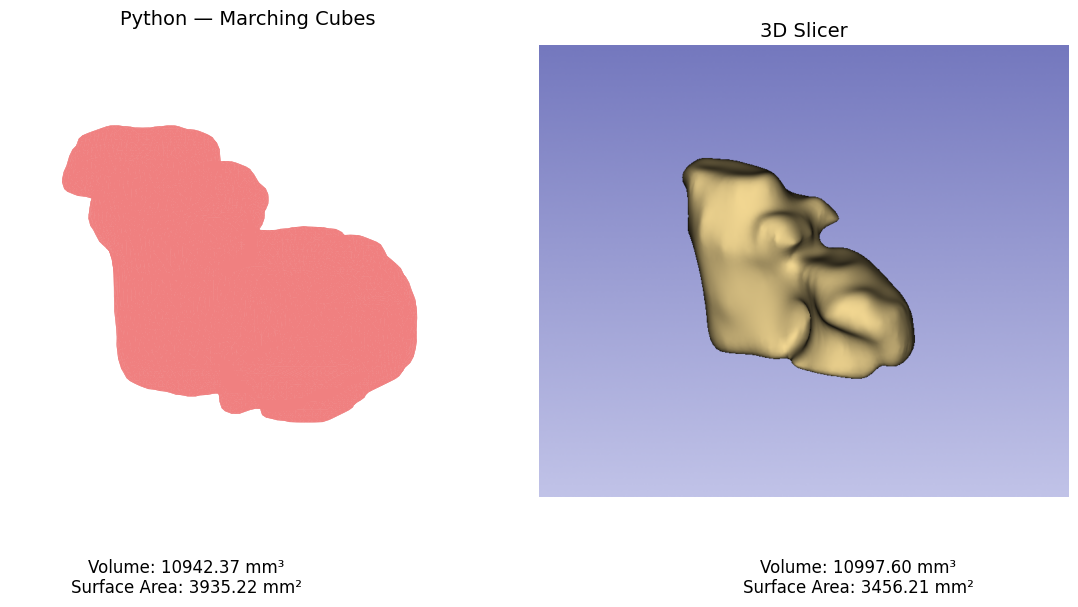

Saved: ../results/figures/python_vs_slicer.png


In [28]:
# Compare smoothed Python 3D mesh with 3D Slicer results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trimesh
from pathlib import Path
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# File paths
slicer_dir = Path("../results/slicer")
slicer_image = slicer_dir / "lymph_node_slicer_000.png"
slicer_csv = slicer_dir / "Table.csv"

# Load Slicer measurements
df = pd.read_csv(slicer_csv)

# Python mesh measurements (original geometry)
mesh = trimesh.Trimesh(vertices=vertices, faces=faces, process=False)
python_volume = abs(mesh.volume) if mesh.is_watertight else np.nan
python_area = mesh.area

# Read Slicer measurements
print("Slicer CSV columns:", df.columns.tolist())
display(df)

# Find measurement columns
volume_cols = [c for c in df.columns if "volume" in c.lower() and "mm3" in c.lower()]
area_cols = [c for c in df.columns if "surface" in c.lower() and "mm2" in c.lower()]

slicer_volume = float(df[volume_cols[0]].iloc[0]) if volume_cols else np.nan
slicer_area = float(df[area_cols[0]].iloc[0]) if area_cols else np.nan

# Smooth mesh for visualization only
smooth_mesh = mesh.copy()
trimesh.smoothing.filter_laplacian(
    smooth_mesh,
    lamb=0.3,
    iterations=5
)

# Plot comparison
fig_compare = plt.figure(figsize=(14, 7))

# Python 3D mesh
ax1 = fig_compare.add_subplot(121, projection="3d")
triangles = smooth_mesh.vertices[smooth_mesh.faces]

collection = Poly3DCollection(
    triangles,
    facecolor="lightcoral",
    edgecolor="none",
    alpha=1
)

ax1.add_collection3d(collection)

mins = smooth_mesh.vertices.min(axis=0)
maxs = smooth_mesh.vertices.max(axis=0)

ax1.set_xlim(mins[0], maxs[0])
ax1.set_ylim(mins[1], maxs[1])
ax1.set_zlim(mins[2], maxs[2])
ax1.set_box_aspect(np.maximum(maxs - mins, 1e-6))

ax1.view_init(elev=25, azim=45)
ax1.set_axis_off()
ax1.set_title("Python — Marching Cubes", fontsize=14)

# 3D Slicer image
ax2 = fig_compare.add_subplot(122)
ax2.imshow(plt.imread(slicer_image))
ax2.axis("off")
ax2.set_title("3D Slicer", fontsize=14)

# Measurements beneath each model
fig_compare.text(
    0.27, 0.08,
    f"Volume: {python_volume:.2f} mm³\n"
    f"Surface Area: {python_area:.2f} mm²",
    ha="center", fontsize=12
)

fig_compare.text(
    0.75, 0.08,
    f"Volume: {slicer_volume:.2f} mm³\n"
    f"Surface Area: {slicer_area:.2f} mm²",
    ha="center", fontsize=12
)

plt.subplots_adjust(bottom=0.2, wspace=0.05)
plt.show()

# Save result
output_path = Path("../results/figures/python_vs_slicer.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig_compare.savefig(output_path, dpi=150, bbox_inches="tight")

print("Saved:", output_path)

# STL

In [ ]:
%pip install trimesh

Note: you may need to restart the kernel to use updated packages.


In [32]:
# Create and export a 3D mesh as STL

import trimesh
from pathlib import Path

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    process=False
)

output_dir = Path("../results/meshes")
output_dir.mkdir(parents=True, exist_ok=True)

stl_path = output_dir / "lymph_node_mesh.stl"

mesh.export(stl_path)

print("STL saved:", stl_path.resolve())
print("Mesh watertight:", mesh.is_watertight)

STL saved: /home/stud/nasrinke/projects/medical-3d-visualization/results/meshes/lymph_node_mesh.stl
Mesh watertight: True
